# Inference-engine throughput — figure

Figure for the inference-engine benchmarking section in `docs/latex/main.tex`:
output throughput (tok/s) by candidate, one bar per engine (vLLM, SGLang), at
concurrency 16. Loads the already-committed
`docs/debug/phase4_inference_benchmark_summary.json` — no GPU needed, this
just plots results already measured and archived elsewhere. See that file's
`meta.methodology_note` for why this is the third (and first trustworthy)
version of this benchmark: the first run compared engines under different
generation-length policies, and the second claimed a fix that the committed
raw files didn't actually reflect.

In [1]:
import json
from pathlib import Path

DEBUG = Path("../docs/debug")
summary = json.loads((DEBUG / "phase4_inference_benchmark_summary.json").read_text())
rows = summary["rows"]
meta = summary["meta"]
assert meta["fixed_output_tokens"] == 512
assert meta["ignore_eos"] is True
for r in rows:
    assert r["mean_output_tokens_per_request"] == 512.0, r
meta

{'vllm_version': '0.32.0',
 'sglang_version': '0.5.22',
 'gpu': 'NVIDIA B300 SXM6 PC',
 'prompt_stats_path': '/root/bonsai/docs/debug/phase4_inference_benchmark_humaneval_ts_prompt_stats.json',
 'fixed_output_tokens': 512,
 'ignore_eos': True,
 'methodology_note': '2026-10-20 B300 HumanEval-TS serving (159 prompts, 512 output tokens, concurrency 1/4/16/32). SGLang: --sharegpt-output-len 512 (ignore EOS by default). vLLM: --custom-output-len 512 --ignore-eos after a VLLM_ONLY=1 re-sweep; earlier committed vLLM raw JSONs were EOS-shortened while summary incorrectly reported 512 until that re-sweep (raw total_output_tokens/159=512).'}

## The figure

Representative concurrency (16), all four candidates, ordered by approximate
parameter count (ascending): `depth0/experts64` (16.03B), `depth16/experts0`
(20.56B), `depth0/experts8` (28.72B), `baseline` (30.5B).

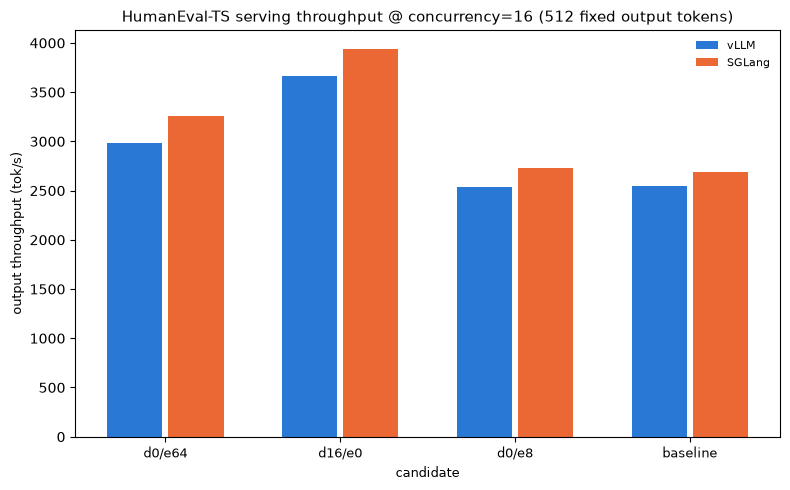

In [2]:
from bonsai.pruning.viz import plot_inference_throughput

REP_CONCURRENCY = 16
ORDER = [
    ("depth0_experts64", "d0/e64"),
    ("depth16_experts0", "d16/e0"),
    ("depth0_experts8", "d0/e8"),
    ("baseline", "baseline"),
]


def pick(engine: str, candidate: str) -> dict:
    for r in rows:
        if (
            r["engine"] == engine
            and r["candidate"] == candidate
            and r["concurrency"] == REP_CONCURRENCY
        ):
            return r
    raise KeyError((engine, candidate))


candidates = [label for _, label in ORDER]
vllm_tok_s = [pick("vllm", slug)["throughput_tok_s"] for slug, _ in ORDER]
sglang_tok_s = [pick("sglang", slug)["throughput_tok_s"] for slug, _ in ORDER]

fig = plot_inference_throughput(
    candidates,
    vllm_tok_s,
    sglang_tok_s,
    title="HumanEval-TS serving throughput @ concurrency=16 (512 fixed output tokens)",
)
fig.savefig("../docs/latex/figures/phase4_inference_throughput.png", dpi=150)
fig.savefig("../docs/latex/figures/phase4_inference_throughput.pdf")